# EDA – MNIST: dữ liệu, cấu trúc không gian và lựa chọn mô hình

*Mọi thống kê dùng để ra quyết định tính trên `splits["train"]`: 50.000 ảnh tách từ 60.000 ảnh train gốc (stratify, seed 42, giống hệt `load_splits`). Notebook này không huấn luyện bộ phân lớp nào. Validation và test chỉ xuất hiện ở mục 0.3–0.5 (kiểm tra chất lượng) và mục 4 (so cấu trúc với train), không dùng để ra quyết định.*

Mục tiêu: tìm những tính chất của dữ liệu gợi ý mô hình nào phù hợp và mỗi mô hình cần xử lý gì. Mỗi mục kết thúc bằng bảng **Hệ quả cho mô hình**; mục 5 gom lại thành lựa chọn trong từng nhóm mà đề cho phép, kèm các giả thuyết để kiểm chứng ở phần thí nghiệm.

0. Dữ liệu đầu vào: nhãn và kiểu dữ liệu, sanity check và chia tập, chất lượng dữ liệu, phân bố lớp
1. Phân bố mực theo vị trí: tần suất có mực, dead pixel, dữ liệu gần nhị phân, ảnh trung bình và độ lệch chuẩn theo lớp, crop, lượng mực theo lớp
2. Tương quan giữa các pixel lân cận → giả định độc lập của Naïve Bayes
3. Độ phân tách lớp: khoảng cách giữa tâm các lớp → các cặp có nguy cơ nhầm; các cặp khác nhau ở đâu; Fisher score theo pixel
4. Kiểm tra validation và test: chỉ so sánh cấu trúc với train
5. Tổng hợp: từ EDA tới lựa chọn mô hình (Multinomial NB, Logistic Regression, Random Forest) và các giả thuyết cho phần thí nghiệm

## **0. Dữ liệu đầu vào**

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Tìm gốc repo (thư mục chứa src/), để notebook chạy được từ bất kỳ thư mục con nào
ROOT = Path.cwd().resolve()
for p in [ROOT, *ROOT.parents]:
    if (p / "src" / "data" / "idx_loader.py").is_file():
        ROOT = p
        break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.idx_loader import DEFAULT_RAW_DIR, load_mnist, read_idx
from src.data.preprocess import load_splits, stratified_split, to_unit_range

RAW = DEFAULT_RAW_DIR                            # data/raw ở gốc repo
FIG_DIR = ROOT / "eda" / "image"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Lưu hình vào eda/image/<name>.png; tên bắt đầu bằng số mục (00_..., 01_..., ...)."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")


rng = np.random.default_rng(42)                  # chọn ảnh ngẫu nhiên để xem

(X_raw, y_raw), (X_test_raw, y_test_raw) = load_mnist()   # 60.000 ảnh train gốc và 10.000 ảnh test (uint8)
train_idx, val_idx = stratified_split(y_raw)              # giống hệt load_splits: stratify, seed 42

# Mọi quyết định (mask, crop) dựa trên đúng tập huấn luyện 50.000 ảnh.
X_raw_tr = X_raw[train_idx]                      # uint8 0..255, dùng khi cần giá trị nguyên
X_train = to_unit_range(X_raw_tr)                # (50000, 28, 28), float32 trong [0, 1]
y_train = y_raw[train_idx].astype(np.int64)      # (50000,), nhãn 0..9

print("train:", X_train.shape)

train: (50000, 28, 28)


### 0.1 Nhãn và việc ghép ảnh – nhãn

In [2]:
label_path = RAW / "train-labels.idx1-ubyte"
y_bytes = np.fromfile(label_path, dtype=np.uint8, offset=8)   # header nhãn dài 8 byte

assert len(y_bytes) == len(X_raw)           # số nhãn == số ảnh
assert np.array_equal(y_bytes, y_raw)     # đọc tay == load_mnist
labels_present = np.unique(y_bytes)
print("Nhãn xuất hiện:", labels_present)
assert np.array_equal(labels_present, np.arange(10))

Nhãn xuất hiện: [0 1 2 3 4 5 6 7 8 9]


### 0.2 Kiểu dữ liệu và miền giá trị

In [3]:
print("Gốc        :", X_raw.dtype, "| min", X_raw.min(), "| max", X_raw.max(),
      "| số mức xám khác nhau:", np.unique(X_raw).size)
print("to_unit_range:", X_train.dtype, "| min", X_train.min(), "| max", X_train.max())

# Vì sao không tính toán trực tiếp trên uint8: cộng/trừ bị tràn và quay vòng
a = X_raw[0, 14, 4:12]
print("uint8        :", a)
print("uint8 - 128  :", a - np.uint8(128))       # 0 - 128 thành 128, sai
print("int16 - 128  :", a.astype(np.int16) - 128)

Gốc        : uint8 | min 0 | max 255 | số mức xám khác nhau: 256
to_unit_range: float32 | min 0.0 | max 1.0
uint8        : [0 0 0 0 0 0 0 0]
uint8 - 128  : [128 128 128 128 128 128 128 128]
int16 - 128  : [-128 -128 -128 -128 -128 -128 -128 -128]


### 0.3 Sanity check và chia train / validation / test

Kiểm tra shape, dtype, miền giá trị, NaN và nhãn trên dữ liệu thô, rồi trên ba tập do `load_splits` trả về. Từ 60.000 ảnh train gốc tách 50.000 train và 10.000 validation (stratify, seed 42); test 10.000 ảnh giữ nguyên.

In [4]:
def sanity_check(X, y, name):
    """Ảnh 28×28, số ảnh = số nhãn, không NaN, pixel trong [0, 255] (uint8) hoặc [0, 1] (float), đủ nhãn 0..9."""
    vmax = 1.0 if np.issubdtype(X.dtype, np.floating) else 255
    assert X.shape[1:] == (28, 28), f"{name}: shape {X.shape}"
    assert len(X) == len(y), f"{name}: {len(X)} ảnh nhưng {len(y)} nhãn"
    assert not np.isnan(X).any(), f"{name}: có NaN"
    assert X.min() >= 0 and X.max() <= vmax, f"{name}: pixel ngoài [0, {vmax}]"
    assert set(np.unique(y).tolist()) == set(range(10)), f"{name}: nhãn {np.unique(y)}"
    print(f"{name:<10}: {X.shape} {y.shape} {X.dtype} range=[{X.min()}, {X.max()}]")


sanity_check(X_raw, y_raw, "train gốc")
sanity_check(X_test_raw, y_test_raw, "test gốc")

splits = load_splits(flat=False)                 # (N, 28, 28), float32 [0, 1]
X_val, y_val = splits["val"]
X_test, y_test = splits["test"]
assert np.array_equal(splits["train"][0], X_train) and np.array_equal(splits["train"][1], y_train)
for name in ("train", "val", "test"):
    sanity_check(*splits[name], name)

train gốc : (60000, 28, 28) (60000,) uint8 range=[0, 255]
test gốc  : (10000, 28, 28) (10000,) uint8 range=[0, 255]


train     : (50000, 28, 28) (50000,) float32 range=[0.0, 1.0]
val       : (10000, 28, 28) (10000,) float32 range=[0.0, 1.0]
test      : (10000, 28, 28) (10000,) float32 range=[0.0, 1.0]


### 0.4 Chất lượng dữ liệu

- **Trùng lặp và rò rỉ**: hai ảnh coi là trùng khi khớp từng byte. Kiểm tra trong 60.000 ảnh train gốc, và giữa train, validation, test.
- **Nhất quán**: dtype, shape, khoảng giá trị và tập nhãn của train gốc so với test.
- **Nhãn đúng**: xem bằng mắt 30 ảnh train ngẫu nhiên kèm nhãn.

In [5]:
from collections import Counter


def image_keys(X):
    return [img.tobytes() for img in X]          # hai ảnh trùng khi khớp từng byte


keys_raw = image_keys(X_raw)
count_raw = Counter(keys_raw)
dup_keys = [k for k, c in count_raw.items() if c > 1]
labels_of = {}
for key, label in zip(keys_raw, y_raw):
    labels_of.setdefault(key, set()).add(int(label))
print(f"Train gốc: {sum(count_raw[k] - 1 for k in dup_keys)} ảnh trùng ({len(dup_keys)} nhóm), "
      f"{sum(len(labels_of[k]) > 1 for k in dup_keys)} nhóm có nhãn mâu thuẫn")

key_sets = {name: set(image_keys(splits[name][0])) for name in ("train", "val", "test")}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a}–{b}: {len(key_sets[a] & key_sets[b])} ảnh trùng")

Train gốc: 0 ảnh trùng (0 nhóm), 0 nhóm có nhãn mâu thuẫn


train–val: 0 ảnh trùng
train–test: 0 ảnh trùng
val–test: 0 ảnh trùng


In [6]:
rows = [
    ("dtype ảnh", str(X_raw.dtype), str(X_test_raw.dtype)),
    ("shape mỗi ảnh", str(X_raw.shape[1:]), str(X_test_raw.shape[1:])),
    ("min, max pixel", f"{X_raw.min()}, {X_raw.max()}", f"{X_test_raw.min()}, {X_test_raw.max()}"),
    ("dtype nhãn", str(y_raw.dtype), str(y_test_raw.dtype)),
    ("các lớp", str(np.unique(y_raw).tolist()), str(np.unique(y_test_raw).tolist())),
]
print(f"{'':<16}{'Train gốc':<31}{'Test':<31}Kết quả")
for name, a, b in rows:
    print(f"{name:<16}{a:<31}{b:<31}{'nhất quán' if a == b else 'KHÁC'}")

                Train gốc                      Test                           Kết quả
dtype ảnh       uint8                          uint8                          nhất quán
shape mỗi ảnh   (28, 28)                       (28, 28)                       nhất quán
min, max pixel  0, 255                         0, 255                         nhất quán
dtype nhãn      uint8                          uint8                          nhất quán
các lớp         [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] nhất quán


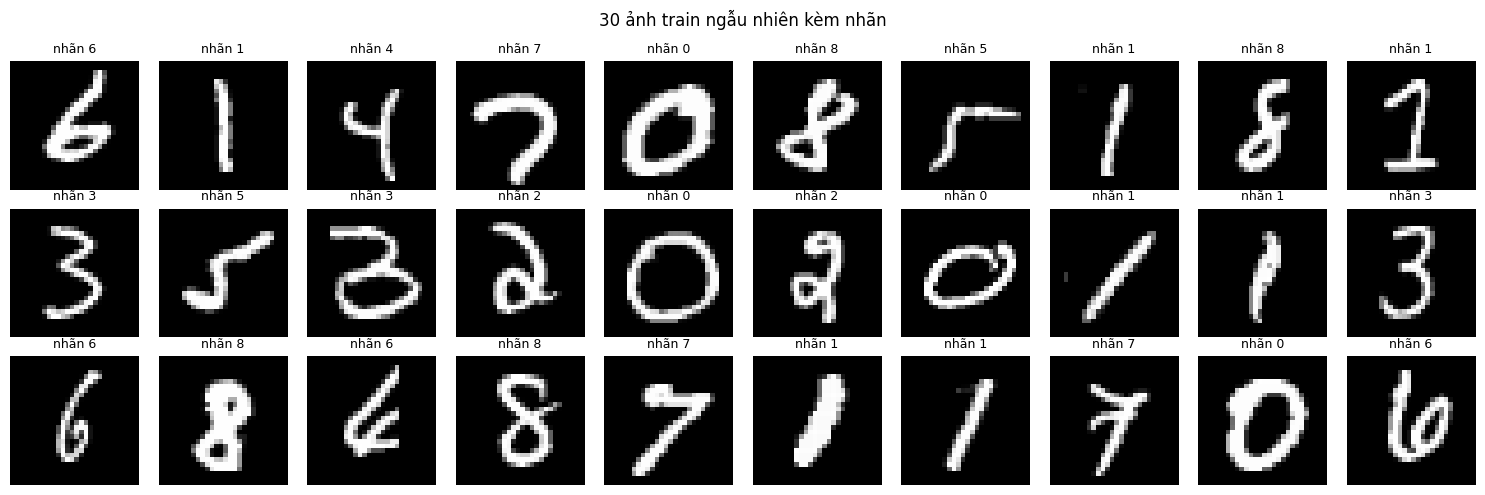

In [7]:
idx = rng.choice(len(X_train), size=30, replace=False)
fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_train[i], cmap="gray")
    ax.set_title(f"nhãn {y_train[i]}", fontsize=9)
    ax.axis("off")
fig.suptitle("30 ảnh train ngẫu nhiên kèm nhãn")
plt.tight_layout()
save_fig(fig, "00_label_check")
plt.show()

### 0.5 Phân bố lớp trên train, validation, test

Lớp    Train (sl)   Train %    Val (sl)     Val %   Test (sl)    Test %
0           4,936     9.87%         987     9.87%         980     9.80%
1           5,618    11.24%       1,124    11.24%       1,135    11.35%
2           4,965     9.93%         993     9.93%       1,032    10.32%
3           5,109    10.22%       1,022    10.22%       1,010    10.10%
4           4,868     9.74%         974     9.74%         982     9.82%
5           4,518     9.04%         903     9.03%         892     8.92%
6           4,932     9.86%         986     9.86%         958     9.58%
7           5,221    10.44%       1,044    10.44%       1,028    10.28%
8           4,876     9.75%         975     9.75%         974     9.74%
9           4,957     9.91%         992     9.92%       1,009    10.09%
Train : max/min = 1.243 (lớp 1 / lớp 5)
Val   : max/min = 1.245 (lớp 1 / lớp 5)
Test  : max/min = 1.272 (lớp 1 / lớp 5)


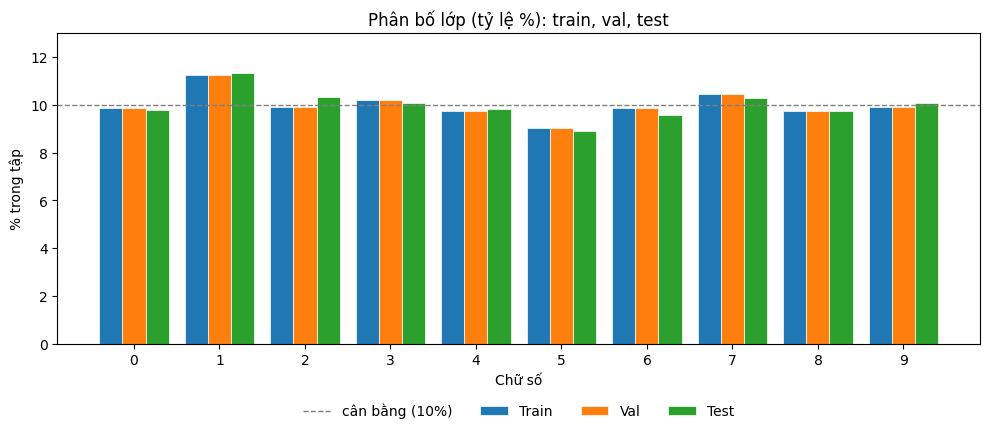

In [8]:
rows = [(name, np.bincount(y, minlength=10)) for name, y in [("Train", y_train), ("Val", y_val), ("Test", y_test)]]

print(f"{'Lớp':<5}" + "".join(f"{n + ' (sl)':>12}{n + ' %':>10}" for n, _ in rows))
for k in range(10):
    print(f"{k:<5}" + "".join(f"{c[k]:>12,}{c[k] / c.sum() * 100:>9.2f}%" for _, c in rows))
for name, c in rows:
    print(f"{name:<6}: max/min = {c.max() / c.min():.3f} (lớp {c.argmax()} / lớp {c.argmin()})")

fig, ax = plt.subplots(figsize=(10, 4.5))
x, width = np.arange(10), 0.27
for j, (name, c) in enumerate(rows):
    ax.bar(x + (j - 1) * width, c / c.sum() * 100, width, label=name, color=f"C{j}", edgecolor="white", linewidth=0.5)
ax.axhline(10, color="gray", linestyle="--", linewidth=1, label="cân bằng (10%)")
ax.set(xticks=x, xlabel="Chữ số", ylabel="% trong tập", ylim=(0, 13), title="Phân bố lớp (tỷ lệ %): train, val, test")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)
plt.tight_layout()
save_fig(fig, "00_class_distribution")
plt.show()

### Kết luận mục 0

**Nhận xét**:

- Định dạng IDX (magic, kiểu uint8, số chiều, kích thước file) do `read_idx` kiểm tra khi đọc. Nhãn đọc thẳng từ file khớp `load_mnist`; có đủ 10 nhãn. Pixel kiểu uint8, nằm trong [0, 255], dùng đủ 256 mức xám.
- **Sanity check, chia tập** (0.3): train gốc, test và ba tập 50.000 / 10.000 / 10.000 đều đạt (shape 28×28, không NaN, pixel trong miền giá trị, đủ nhãn 0–9). Sau `to_unit_range` là float32 trong [0, 1].
- **Chất lượng** (0.4): không có ảnh trùng trong 60.000 ảnh train gốc, không có ảnh trùng giữa train, validation và test (không rò rỉ dữ liệu). Train gốc và test nhất quán về dtype, shape, khoảng giá trị, tập nhãn. Trong 30 ảnh ngẫu nhiên, 29 ảnh có nhãn khớp rõ với nội dung; ảnh còn lại (nhãn 8) có nét đậm tới mức thành một khối, khó đọc nhưng không mâu thuẫn với nhãn. Đây chỉ là kiểm tra thô trên mẫu nhỏ, không chứng minh cho toàn bộ tập.
- **Phân bố lớp** (0.5): mỗi lớp chiếm 8,9–11,4% ở cả ba tập; số 1 nhiều nhất, số 5 ít nhất, max/min = 1,243 (train), 1,245 (val), 1,272 (test). Tỷ lệ từng lớp của validation khớp train (stratify).

**Hệ quả cho mô hình**
- Mọi notebook và code huấn luyện đều đi qua `load_mnist` / `load_splits`, không đọc file trực tiếp.
- Không tính toán trên mảng uint8 (cộng/trừ bị tràn, ví dụ khi trừ trung bình để standardize); luôn dùng bản float32 sau `to_unit_range`.
- Dữ liệu sạch và gần cân bằng: không cần loại mẫu hay resampling; accuracy và F1 macro đều phản ánh đúng chất lượng mô hình, và chọn siêu tham số trên validation là có cơ sở.

## **1. Phân bố mực theo vị trí**

Nhóm quan tâm:
- Trên lưới 28×28, mực nằm ở đâu? Vị trí nào không bao giờ có mực (dead pixel)?
- Chữ viết tay của mỗi con số thường như thế nào? Hay mỗi lớp trông "trung bình" ra sao, và các ảnh trong cùng một lớp khác nhau ở đâu?

**Định nghĩa.**
- *Có mực* tại (i, j) trong một ảnh: pixel (i, j) > 0. Mọi mức xám đều tính, vì pixel xám là mép nét chữ.
- *Tần suất có mực* tại (i, j): tỷ lệ ảnh có mực tại (i, j).
- *Dead pixel*: tần suất bằng 0 (pixel bằng 0 ở mọi ảnh, phương sai bằng 0). *Gần như chết*: tần suất dương nhưng dưới 0,1%.
- *Lượng mực*: tổng cường độ pixel (thang [0, 1]), nên pixel xám nhạt chỉ góp một phần nhỏ. "Tỷ lệ mực trong khung 20×20" và "lượng mực trung bình của lớp" dùng định nghĩa này.

### 1.1 Tần suất có mực và dead pixel

Dead: 72
Gần như chết (<0.1%): 116


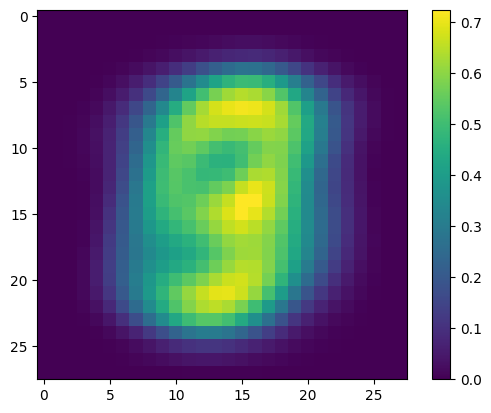

In [9]:
freq = (X_train > 0).mean(axis=0)          # (28, 28): tỷ lệ ảnh có mực tại mỗi vị trí
print("Dead:", (freq == 0).sum())
print("Gần như chết (<0.1%):", ((freq > 0) & (freq < 0.001)).sum())
plt.imshow(freq, cmap="viridis"); plt.colorbar(); plt.show()

Ở thang tuyến tính, toàn bộ vùng viền có cùng một màu tối: không phân biệt được vị trí chết hẳn với vị trí có mực ở vài chục ảnh. Hình dưới vẽ lại bằng thang log và tô riêng từng nhóm.

Dead         :  72 / 784 vị trí (9.2%)
Gần như chết : 116 vị trí, mỗi vị trí có mực ở 1–47 ảnh


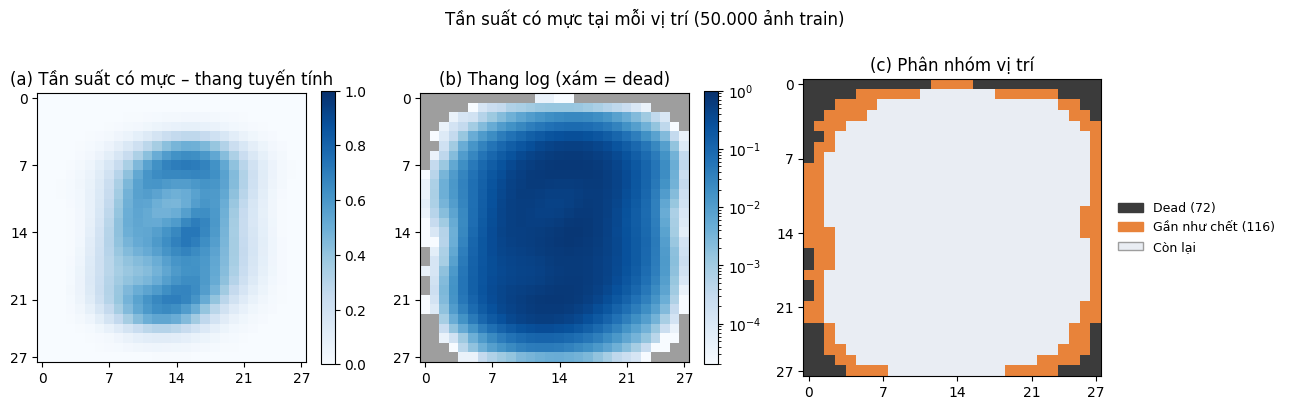

In [10]:
from matplotlib.colors import LogNorm, ListedColormap
from matplotlib.patches import Patch

n_img = len(X_train)
dead = freq == 0
near = (freq > 0) & (freq < 0.001)
n_with_ink = np.rint(freq * n_img).astype(int)          # số ảnh có mực tại mỗi vị trí

print(f"Dead         : {dead.sum():3d} / 784 vị trí ({dead.mean():.1%})")
print(f"Gần như chết : {near.sum():3d} vị trí, mỗi vị trí có mực ở "
      f"{n_with_ink[near].min()}–{n_with_ink[near].max()} ảnh")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

im = axes[0].imshow(freq, cmap="Blues", vmin=0, vmax=1)
axes[0].set_title("(a) Tần suất có mực – thang tuyến tính")
fig.colorbar(im, ax=axes[0], fraction=0.046)

freq_masked = np.ma.masked_where(dead, freq)             # dead pixel không có log -> tô xám
cmap_log = plt.get_cmap("Blues").copy(); cmap_log.set_bad("#9e9e9e")
im = axes[1].imshow(freq_masked, cmap=cmap_log, norm=LogNorm(vmin=1 / n_img, vmax=1))
axes[1].set_title("(b) Thang log (xám = dead)")
fig.colorbar(im, ax=axes[1], fraction=0.046)

groups = np.where(dead, 0, np.where(near, 1, 2))
colors = ["#3b3b3b", "#e8833a", "#e9edf3"]
axes[2].imshow(groups, cmap=ListedColormap(colors), vmin=0, vmax=2)
axes[2].set_title("(c) Phân nhóm vị trí")
axes[2].legend(handles=[Patch(color=colors[0], label=f"Dead ({dead.sum()})"),
                        Patch(color=colors[1], label=f"Gần như chết ({near.sum()})"),
                        Patch(facecolor=colors[2], edgecolor="#9e9e9e", label="Còn lại")],
               loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=9)

for ax in axes:
    ax.set_xticks([0, 7, 14, 21, 27]); ax.set_yticks([0, 7, 14, 21, 27])
fig.suptitle(f"Tần suất có mực tại mỗi vị trí ({n_img:,} ảnh train)".replace(",", "."))
plt.tight_layout()
save_fig(plt.gcf(), "01_ink_frequency")
plt.show()

**Dead pixel nằm ở đâu?** Đo theo "vòng" tính từ viền: vòng 0 là hàng/cột ngoài cùng, vòng 4 là viền của khung 20×20 ở giữa. Nếu dead pixel là hệ quả của cách MNIST đặt chữ số (co về 20×20 rồi đặt vào 28×28 theo tâm khối lượng) thì chúng phải dồn ở các vòng ngoài và ở góc.

In [11]:
r, c = np.indices((28, 28))
ring = np.minimum.reduce([r, c, 27 - r, 27 - c])        # 0 = viền ngoài cùng, 13 = tâm

print("vòng | số vị trí | dead | gần như chết | tần suất TB")
for k in range(6):
    m = ring == k
    print(f"{k:4d} | {m.sum():9d} | {dead[m].sum():4d} | {near[m].sum():12d} | {freq[m].mean():.4f}")
print("Dead ở vòng ≥ 4 (bên trong khung 20×20):", dead[ring >= 4].sum())

corner = (np.minimum(r, 27 - r) < 4) & (np.minimum(c, 27 - c) < 4)   # 4 khối 4×4 ở góc
print(f"Dead ở 4 góc 4×4: {dead[corner].sum()} / {corner.sum()} vị trí góc")

ink = X_train.sum(axis=0)                                # tổng mực tại mỗi vị trí
print(f"Tỷ lệ tổng mực nằm trong khung 20×20 ở giữa: {ink[4:24, 4:24].sum() / ink.sum():.2%}")
rows_any = np.flatnonzero((freq > 0).any(axis=1))
cols_any = np.flatnonzero((freq > 0).any(axis=0))
print(f"Hàng có mực ở ít nhất 1 ảnh: {rows_any.min()}..{rows_any.max()} | "
      f"cột: {cols_any.min()}..{cols_any.max()}")

vòng | số vị trí | dead | gần như chết | tần suất TB
   0 |       108 |   54 |           43 | 0.0004
   1 |       100 |   17 |           46 | 0.0041
   2 |        92 |    1 |           23 | 0.0150
   3 |        84 |    0 |            4 | 0.0491
   4 |        76 |    0 |            0 | 0.1235
   5 |        68 |    0 |            0 | 0.2225
Dead ở vòng ≥ 4 (bên trong khung 20×20): 0
Dead ở 4 góc 4×4: 43 / 64 vị trí góc
Tỷ lệ tổng mực nằm trong khung 20×20 ở giữa: 96.66%
Hàng có mực ở ít nhất 1 ảnh: 0..27 | cột: 0..27


**Độ lệch chuẩn của từng pixel.** Chuẩn hoá z-score *từng pixel* chia cho std của pixel đó. Ô dưới xem std ở dead pixel và pixel gần như chết so với phần còn lại.

In [12]:
std_all = X_train.std(axis=0)                            # (28, 28): std của từng pixel trên 50k ảnh
print(f"Pixel có std = 0: {(std_all == 0).sum()} | trùng khớp với dead pixel: {np.array_equal(std_all == 0, dead)}")
print(f"std trung vị: {near.sum()} pixel gần như chết = {np.median(std_all[near]):.4f} | "
      f"pixel có mực ở ≥ 0,1% ảnh = {np.median(std_all[freq >= 0.001]):.3f}")

Pixel có std = 0: 72 | trùng khớp với dead pixel: True
std trung vị: 116 pixel gần như chết = 0.0047 | pixel có mực ở ≥ 0,1% ảnh = 0.272


**Dữ liệu gần nhị phân.** Pixel xám là mép nét chữ bị khử răng cưa khi co ảnh về 20×20. Ô dưới xem giá trị khác 0 phân bố ra sao: nếu phần lớn là 0 hoặc rất đậm thì dữ liệu gần nhị phân.

In [13]:
nz = X_raw_tr[X_raw_tr > 0]
print(f"Pixel bằng 0: {(X_raw_tr == 0).mean():.2%} tổng số pixel")
for lo, hi in [(1, 25), (26, 127), (128, 255)]:
    print(f"  giá trị {lo:3d}–{hi:3d}: {((nz >= lo) & (nz <= hi)).mean():.1%} số pixel khác 0")

Pixel bằng 0: 80.86% tổng số pixel
  giá trị   1– 25: 8.9% số pixel khác 0
  giá trị  26–127: 21.9% số pixel khác 0
  giá trị 128–255: 69.2% số pixel khác 0


### 1.2 Ảnh trung bình và độ lệch chuẩn theo lớp

Mười ảnh train ngẫu nhiên của mỗi lớp, để thấy mức đa dạng trong lớp trước khi tóm tắt bằng ảnh trung bình và độ lệch chuẩn.

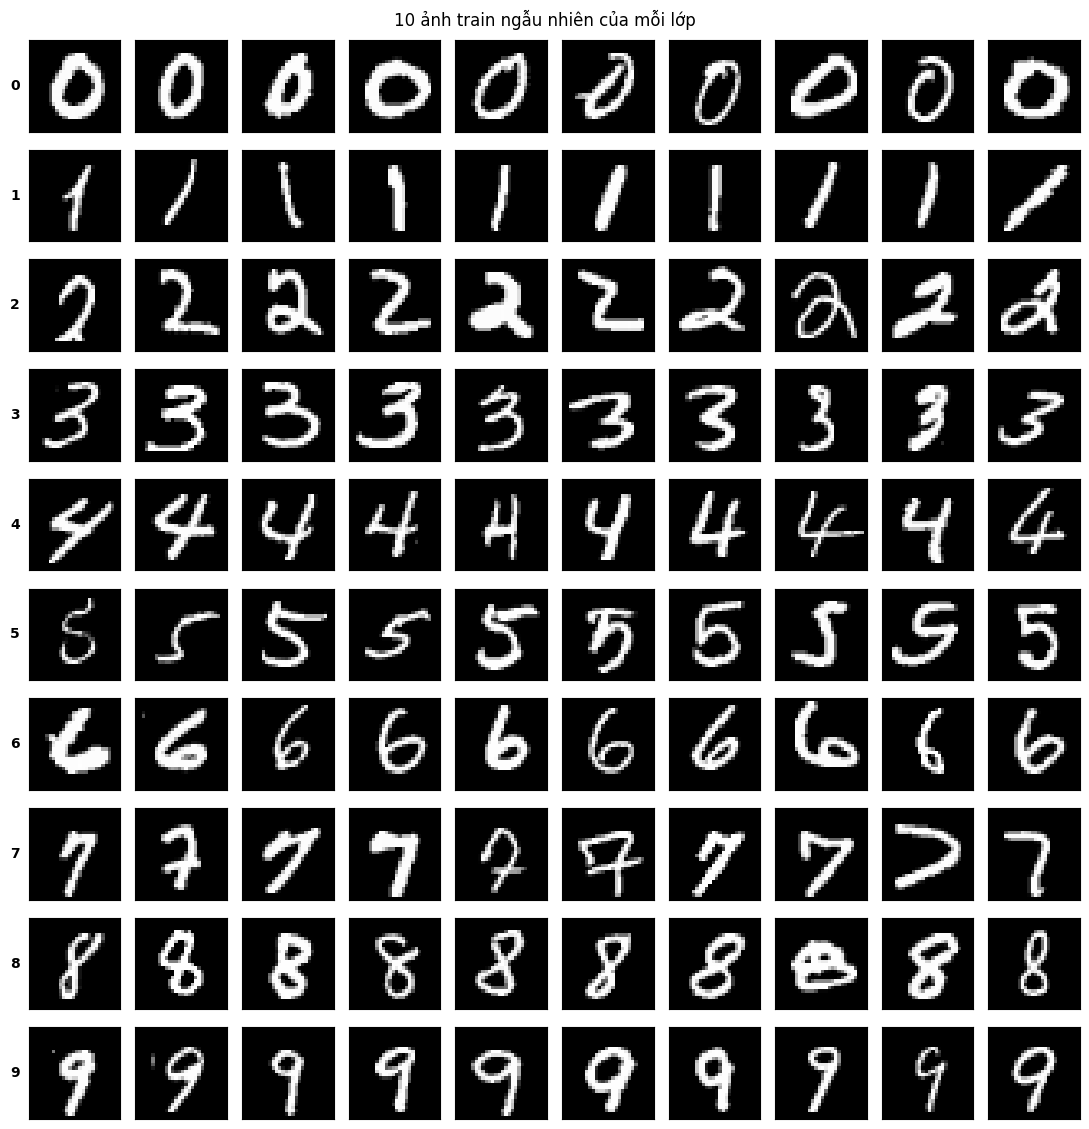

In [14]:
fig, axes = plt.subplots(10, 10, figsize=(11, 11.5))
for k in range(10):
    for ax, i in zip(axes[k], rng.choice(np.flatnonzero(y_train == k), 10, replace=False)):
        ax.imshow(X_train[i], cmap="gray")
        ax.set_xticks([]); ax.set_yticks([])
    axes[k, 0].set_ylabel(str(k), rotation=0, labelpad=10, va="center", fontweight="bold")
fig.suptitle("10 ảnh train ngẫu nhiên của mỗi lớp")
plt.tight_layout()
save_fig(fig, "01_samples")
plt.show()

Hàng trên: ảnh trung bình của mỗi lớp (đậm = vị trí thường có mực). Hàng dưới: độ lệch chuẩn theo pixel (đậm = các ảnh trong lớp khác nhau nhiều ở vị trí đó). Con số dưới mỗi ảnh std là **tổng phương sai trong lớp** (tổng σ² trên 784 pixel).

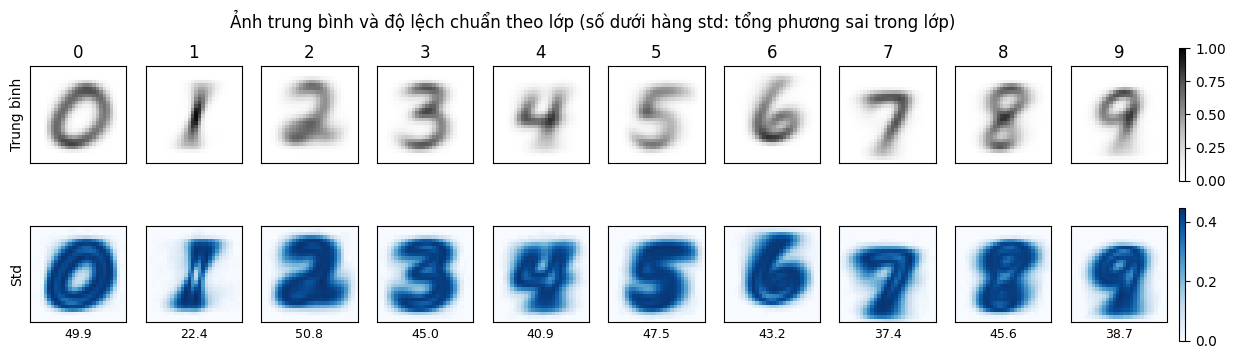

Lớp xếp theo tổng phương sai trong lớp:
  1:   22.4
  7:   37.4
  9:   38.7
  4:   40.9
  6:   43.2
  3:   45.0
  8:   45.6
  5:   47.5
  0:   49.9
  2:   50.8


In [15]:
means = np.stack([X_train[y_train == k].mean(axis=0) for k in range(10)])
stds = np.stack([X_train[y_train == k].std(axis=0) for k in range(10)])
spread = (stds ** 2).sum(axis=(1, 2))                    # tổng phương sai trong lớp

fig, axes = plt.subplots(2, 10, figsize=(15, 3.8))
for k in range(10):
    im_m = axes[0, k].imshow(means[k], cmap="Greys", vmin=0, vmax=1)
    axes[0, k].set_title(str(k))
    im_s = axes[1, k].imshow(stds[k], cmap="Blues", vmin=0, vmax=stds.max())
    axes[1, k].set_xlabel(f"{spread[k]:.1f}", fontsize=9)
    for ax in axes[:, k]:
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("Trung bình", fontsize=10)
axes[1, 0].set_ylabel("Std", fontsize=10)
fig.colorbar(im_m, ax=axes[0, :], fraction=0.012, pad=0.01)
fig.colorbar(im_s, ax=axes[1, :], fraction=0.012, pad=0.01)
fig.suptitle("Ảnh trung bình và độ lệch chuẩn theo lớp (số dưới hàng std: tổng phương sai trong lớp)")
save_fig(plt.gcf(), "01_class_mean_std")
plt.show()

order = np.argsort(spread)
print("Lớp xếp theo tổng phương sai trong lớp:")
for k in order:
    print(f"  {k}: {spread[k]:6.1f}")

### 1.3 Crop và lượng mực theo lớp

**Nếu crop thì nên crop đến đâu?** Khung 20×20 chỉ chứa 96,66% tổng mực (ô vòng ở 1.1), tức bỏ 3,34% lượng mực. Lượng mực bị bỏ không đồng nghĩa với thông tin phân lớp bị mất, nên ảnh hưởng của crop 20×20 phải đo trên validation. Ứng viên ít rủi ro hơn là khung 24×24: bỏ đúng hai vòng ngoài cùng, nơi chứa 71 / 72 dead pixel, và giảm số đặc trưng từ 784 xuống 576 (−27%). Ô dưới đo khung này giữ lại bao nhiêu phần trăm mực, và lượng mực trung bình của từng lớp (dùng ở 5.1).

In [16]:
ink_in_24 = ink[2:26, 2:26].sum() / ink.sum()
print(f"Tỷ lệ mực trong khung 24×24 (bỏ vòng 0–1): {ink_in_24:.2%}")

ink_per_class = means.sum(axis=(1, 2))           # lượng mực trung bình của mỗi lớp
print("Lượng mực trung bình mỗi ảnh:", {k: round(float(ink_per_class[k]), 1) for k in range(10)})

Tỷ lệ mực trong khung 24×24 (bỏ vòng 0–1): 99.76%
Lượng mực trung bình mỗi ảnh: {0: 135.8, 1: 59.5, 2: 117.0, 3: 111.0, 4: 95.3, 5: 101.0, 6: 107.9, 7: 89.9, 8: 117.8, 9: 96.3}


### Kết luận mục 1

**Nhận xét** (trên `splits["train"]`, 50.000 ảnh)

- **Dead pixel**: 72/784 vị trí (9,2%), thêm 116 vị trí gần như chết (mỗi vị trí có mực ở 1–47 ảnh). Cả 72 dead pixel nằm ở ba vòng ngoài cùng (54 ở vòng 0, 17 ở vòng 1, 1 ở vòng 2), 43 ở 4 góc 4×4; bên trong khung 20×20 không có vị trí nào chết hay gần như chết. Điều này khớp với cách tạo MNIST (co về 20×20, căn theo tâm khối lượng): chữ chỉ thỉnh thoảng lệch ra viền, nhưng hàng và cột nào cũng có mực ở ít nhất một ảnh.
- **Độ lệch chuẩn từng pixel**: std = 0 đúng ở 72 dead pixel; 116 pixel gần như chết có std trung vị 0,0047, so với 0,27 ở các pixel còn lại. Chuẩn hoá z-score từng pixel sẽ chia cho 0 ở dead pixel và phóng to các pixel gần như chết khoảng 60 lần.
- **Crop**: khung 20×20 chứa 96,66% lượng mực, khung 24×24 chứa 99,76%. Crop 24×24 giảm 27% số đặc trưng (784 → 576) và chỉ mất 0,24% lượng mực; crop 20×20 giảm 49% (784 → 400) và mất 3,34% lượng mực. Cả hai đều là ứng viên, chọn trên validation.
- **Hiệp phương sai khác nhau giữa các lớp**: tổng phương sai trong lớp từ 22,4 (lớp 1) đến 50,8 (lớp 2): các lớp phân tán khác nhau nhiều, lớp 2 gấp hơn hai lần lớp 1. Khi hai lớp phân tán khác nhau, ranh giới tốt nhất giữa chúng bị cong chứ không phải một siêu phẳng, nên Multinomial NB và Logistic Regression (ranh giới tuyến tính) có thể có trần mà Random Forest, MLP vượt qua được (H2).
- **Lượng mực theo lớp**: số 0 nhiều mực nhất (135,8), số 1 ít nhất (59,5), gấp khoảng 2,3 lần; các lớp còn lại từ 90 đến 118.
- **Gần nhị phân**: 80,86% pixel bằng 0; trong số pixel khác 0, 69,2% có giá trị ≥ 128, chỉ khoảng 31% là xám (mép nét).
- **Ảnh mẫu** (1.2): trong cùng một lớp, vị trí và độ dày nét lệch nhau vài pixel giữa các ảnh, nên cùng một nét có thể rơi vào các pixel khác nhau.

**Hệ quả cho mô hình**

| Phát hiện | Ảnh hưởng | Cách xử lý |
|---|---|---|
| Pixel không âm, gần nhị phân: 80,86% pixel bằng 0; trong số pixel khác 0, 69,2% có giá trị ≥ 128 | Multinomial NB: phù hợp, vì mô hình coi đặc trưng là "lượng" (ở đây là lượng mực) và không giả định hình dạng phân phối. Gaussian NB: giả định mỗi pixel có phân phối chuẩn trong từng lớp, trái với phân phối dồn về hai đầu này | Multinomial NB dùng thẳng pixel [0, 1], không chuẩn hoá |
| 72 dead pixel (phương sai 0) | Multinomial NB: x = 0 trên toàn train nên không đóng góp gì. Logistic Regression, MLP: ở thang [0, 1], gradient bằng 0 nên trọng số đứng yên; sau chuẩn hoá vô hướng, dead pixel thành một hằng số khác 0 ở mọi ảnh (xem `PixelMask`), tức một cột bias thừa: không mang thông tin nhưng vẫn được cập nhật và bị L2 phạt. Random Forest: đặc trưng hằng nên không bao giờ được chọn để chia nhánh. Riêng chuẩn hoá *từng pixel* sẽ chia cho std = 0 | Bỏ 72 cột (mặt nạ tính trên train) hoặc giữ nguyên; Logistic Regression và MLP dùng chuẩn hoá **vô hướng** (một mean, một std cho mọi pixel, fit trên train) |
| 116 pixel gần như chết (chỉ có mực ở 1–47 ảnh) | Multinomial NB: phần lớn các lớp có tổng mực bằng 0 tại các vị trí này, nên xác suất ước lượng bằng 0 và log bằng −∞ khi một ảnh mới có mực ở đó. Logistic Regression, MLP: học từ vài chục ảnh nên dễ khớp nhiễu. Random Forest: một phép chia trên pixel này chỉ tách ra tối đa 49 ảnh, nên chỉ có lợi ở các nút nhỏ, tầng sâu; phương sai của các phép chia đó được giảm bằng cách lấy trung bình nhiều cây | Multinomial NB: làm trơn Laplace (α > 0). Logistic Regression, MLP: L2. Random Forest: không bắt buộc; `min_samples_leaf`, giới hạn độ sâu là siêu tham số để thử trên validation |
| 99,76% mực nằm trong 24×24 | Random Forest: mỗi nút chỉ xét m = √d pixel nên bỏ pixel giảm m không nhiều (28 → 24); lợi ích chính là bớt các pixel viền, vốn hằng ở hầu hết các nút nên cây phải đọc rồi bỏ qua. Mức tiết kiệm cần đo; Logistic Regression giảm số trọng số | Ứng viên: crop 24×24 (784 → 576 đặc trưng) hoặc 20×20 (784 → 400) |
| Lượng mực khác nhau nhiều giữa các lớp (số 0: 135,8; số 1: 59,5) | Multinomial NB không dùng trực tiếp thông tin này: tham số của mỗi lớp được chuẩn hoá về tổng bằng 1, tức mô hình học *mực nằm ở đâu*, không học *bao nhiêu mực* | Để ý khi đọc lỗi của Multinomial NB |
| Hiệp phương sai khác nhau giữa các lớp | Ranh giới tuyến tính (Multinomial NB, Logistic Regression) có thể có trần | Có ít nhất một mô hình phi tuyến (Random Forest, MLP) để so với Logistic Regression |
| Vị trí nét lệch vài pixel trong cùng lớp | Multinomial NB, Logistic Regression, Random Forest, MLP đều gắn mỗi trọng số / phép chia với một vị trí pixel cố định | CNN (phần nâng cao, 5.4) |

Mọi mask và vùng crop đều tính trên `splits["train"]` rồi áp dụng nguyên cho val và test. Crop 24×24 hay loại pixel tần suất thấp chỉ được chốt sau khi so sánh trên validation.

## **2. Tương quan giữa các pixel lân cận**

Naive Bayes giả định các pixel **độc lập có điều kiện khi biết lớp**: $P(x \mid y) = \prod_i P(x_i \mid y)$. Mục này kiểm tra giả định đó:

- Tương quan giữa hai pixel giảm thế nào theo khoảng cách?
- Tương quan còn lại bao nhiêu **trong cùng một lớp**? Đây mới là điều NB giả định. Tương quan tính trên toàn tập bị thổi phồng vì các lớp có hình dạng khác nhau.
- Hệ quả: NB sai ở đâu khi giả định này bị vi phạm, và mô hình nào không cần giả định này?

Chỉ dùng pixel có tần suất có mực ≥ 0,1%. Dead pixel có std = 0 nên không tính được tương quan, còn pixel gần như chết chỉ có dưới 50 ảnh (0,1% của 50.000) nên ước lượng tương quan là nhiễu.

### 2.1. Tương quan theo khoảng cách

Số pixel dùng để tính tương quan: 596


khoảng cách | số cặp | r trung bình | tỷ lệ r > 0.5
          1 |   1138 |        0.708 | 94.5%
         √2 |   1108 |        0.538 | 63.8%
          2 |   1084 |        0.371 | 17.7%
          3 |   1030 |        0.161 | 1.1%
          5 |   2724 |        0.001 | 0.0%
         10 |   1934 |       -0.006 | 0.0%
         20 |    598 |        0.043 | 0.0%


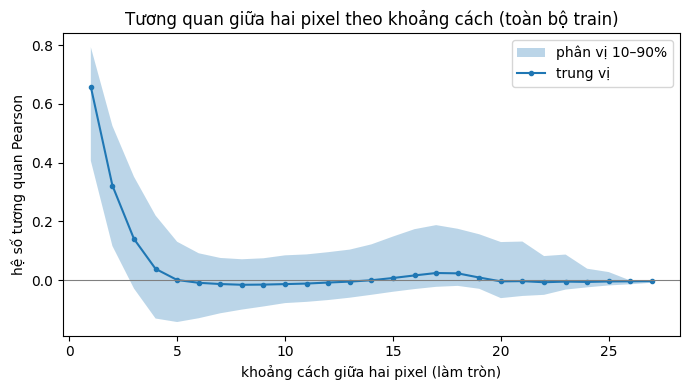

In [17]:
X_train_flat = X_train.reshape(len(X_train), -1)                   # (50000, 784)
core = (freq >= 0.001).ravel()
idx = np.flatnonzero(core)
print("Số pixel dùng để tính tương quan:", core.sum())

def corr_matrix(A):
    A = A - A.mean(axis=0)
    s = A.std(axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        return (A.T @ A) / len(A) / np.outer(s, s)

C = corr_matrix(X_train_flat[:, core])
rr, cc = np.divmod(idx, 28)
D = np.hypot(rr[:, None] - rr[None], cc[:, None] - cc[None])
iu = np.triu_indices(len(idx), k=1)
d, rho = D[iu], C[iu]

print("khoảng cách | số cặp | r trung bình | tỷ lệ r > 0.5")
for v, name in [(1, "1"), (np.sqrt(2), "√2"), (2, "2"), (3, "3"), (5, "5"), (10, "10"), (20, "20")]:
    m = np.isclose(d, v)
    print(f"{name:>11} | {m.sum():6d} | {rho[m].mean():12.3f} | {(rho[m] > 0.5).mean():.1%}")

db = np.rint(d).astype(int)
ks = np.arange(1, 28)
med = np.array([np.median(rho[db == k]) for k in ks])
p10 = np.array([np.percentile(rho[db == k], 10) for k in ks])
p90 = np.array([np.percentile(rho[db == k], 90) for k in ks])

fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(ks, p10, p90, alpha=0.3, label="phân vị 10–90%")
ax.plot(ks, med, "o-", ms=3, label="trung vị")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("khoảng cách giữa hai pixel (làm tròn)"); ax.set_ylabel("hệ số tương quan Pearson")
ax.set_title("Tương quan giữa hai pixel theo khoảng cách (toàn bộ train)")
ax.legend()
plt.tight_layout()
save_fig(plt.gcf(), "02_corr_vs_distance")
plt.show()

### 2.2 Tương quan trong từng lớp

Tương quan tính trên toàn tập gồm hai phần: tương quan do nét bút liền mạch (vẫn còn khi đã biết lớp) và tương quan do khác biệt giữa các lớp (biến mất khi đã biết lớp). Chỉ phần thứ nhất vi phạm giả định của NB.

Trung vị r với pixel bên phải: 0.732
Trung vị r với pixel bên dưới: 0.730
       | r phải (trung vị) | r dưới (trung vị)
toàn bộ |             0.732 | 0.730
 lớp 0 |             0.719 | 0.772


 lớp 1 |             0.654 | 0.863
 lớp 2 |             0.786 | 0.679
 lớp 3 |             0.779 | 0.669


 lớp 4 |             0.656 | 0.799
 lớp 5 |             0.789 | 0.644


 lớp 6 |             0.695 | 0.771
 lớp 7 |             0.727 | 0.760


 lớp 8 |             0.709 | 0.728
 lớp 9 |             0.681 | 0.786


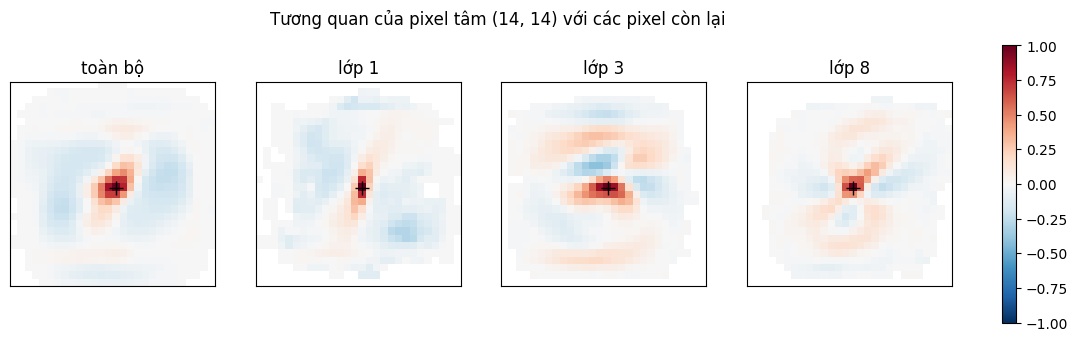

In [18]:
def neighbor_corr(X3, di, dj):
    """Tương quan giữa pixel (i, j) và (i+di, j+dj), tính trên các ảnh của X3."""
    a = X3[:, :28 - di, :28 - dj]; b = X3[:, di:, dj:]
    a = a - a.mean(0); b = b - b.mean(0)
    with np.errstate(invalid="ignore", divide="ignore"):
        return (a * b).mean(0) / (a.std(0) * b.std(0))

ok = freq >= 0.001
r_right, valid_r = neighbor_corr(X_train, 0, 1), ok[:, :-1] & ok[:, 1:]
r_down,  valid_d = neighbor_corr(X_train, 1, 0), ok[:-1, :] & ok[1:, :]
print(f"Trung vị r với pixel bên phải: {np.median(r_right[valid_r]):.3f}")
print(f"Trung vị r với pixel bên dưới: {np.median(r_down[valid_d]):.3f}")

print(f"{'':>6} | r phải (trung vị) | r dưới (trung vị)")
print(f"{'toàn bộ':>6} | {np.median(r_right[valid_r]):17.3f} | {np.median(r_down[valid_d]):.3f}")
for k in range(10):
    Xk = X_train[y_train == k]
    okk = (Xk > 0).mean(0) >= 0.01                         # có mực ở ≥ 1% ảnh của lớp
    rk, dk = neighbor_corr(Xk, 0, 1), neighbor_corr(Xk, 1, 0)
    vr, vd = okk[:, :-1] & okk[:, 1:], okk[:-1] & okk[1:]
    print(f"{'lớp ' + str(k):>6} | {np.median(rk[vr]):17.3f} | {np.median(dk[vd]):.3f}")

def corr_with(A, p):
    """Tương quan giữa pixel p và mọi pixel khác."""
    A = A - A.mean(0); v = A[:, p]
    with np.errstate(invalid="ignore", divide="ignore"):
        return ((A * v[:, None]).mean(0) / (A.std(0) * v.std())).reshape(28, 28)

p = 14 * 28 + 14                                          # pixel tâm
panels = [("toàn bộ", X_train_flat)] + [(f"lớp {k}", X_train_flat[y_train == k]) for k in (1, 3, 8)]
fig, axes = plt.subplots(1, len(panels), figsize=(13, 3.6))
for ax, (t, A) in zip(axes, panels):
    im = ax.imshow(corr_with(A, p), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.plot(14, 14, "k+", ms=10); ax.set_title(t)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.015)
fig.suptitle("Tương quan của pixel tâm (14, 14) với các pixel còn lại")
save_fig(plt.gcf(), "02_center_pixel_corr")
plt.show()

### Kết luận mục 2

**Nhận xét** (596 pixel có tần suất ≥ 0,1%)

- **Tương quan cục bộ mạnh**: hai pixel kề nhau có r trung bình 0,708 (94,5% số cặp có r > 0,5); kề chéo (√2) là 0,538. r giảm còn 0,161 ở khoảng cách 3 và ≈ 0 từ khoảng cách 5, tức tầm tương quan xấp xỉ độ dày nét chữ.
- **Tương quan xa do hình dạng chữ số**: r hơi âm ở khoảng cách 6–12 (nét chữ ở chỗ này thì không ở chỗ bên cạnh) và nhô lên quanh khoảng cách 15–19, xấp xỉ bề ngang một chữ số (hai bên một vòng kín cùng có mực). Hình tương quan của pixel tâm trong lớp 3 có các dải xen kẽ trải hết chiều cao chữ số.
- **Tương quan theo hướng nét**: số 1 có r dưới 0,863 so với r phải 0,654; số 2, 3, 5 ngược lại (r phải ≈ 0,78, r dưới ≈ 0,64–0,68).
- **Tương quan không mất đi khi biết lớp**: trung vị r kề nhau trong từng lớp là 0,64–0,86, ngang mức toàn bộ (0,73). Phần lớn tương quan cục bộ đến từ nét bút liền mạch, không phải từ khác biệt giữa các lớp, nên giả định của NB bị vi phạm thật sự.

**Hệ quả cho mô hình**

| Phát hiện | Ảnh hưởng | Cách xử lý |
|---|---|---|
| Tương quan mạnh *trong cùng lớp* (trung vị 0,64–0,86) | Naive Bayes, cả Gaussian lẫn Multinomial: các pixel kề nhau trên cùng một nét bút bị cộng như nhiều bằng chứng độc lập, nên xác suất hậu nghiệm bị đẩy về gần 0 hoặc 1 | Không sửa được bên trong NB. Khi đánh giá mô hình, nên đo thêm log-loss và tỷ lệ dự đoán sai nhưng có xác suất rất cao. Đây chính là điểm Logistic Regression khắc phục: nó tối ưu trực tiếp P(y \| x), không cần giả định độc lập |
| Đặc trưng tương quan cao (đa cộng tuyến) | Logistic Regression: trọng số không ổn định, ảnh trọng số lốm đốm; bài toán tối ưu có điều kiện số xấu nên gradient descent hội tụ chậm | L2; theo dõi loss theo vòng lặp để chọn learning rate và số vòng |
| Thông tin trùng lặp giữa các pixel lân cận | Random Forest: độ quan trọng bị chia cho các pixel lân cận, bản đồ feature importance bị loang. Mặt khác, vì thông tin có ở nhiều pixel, một tập con ngẫu nhiên các pixel vẫn thường chứa pixel hữu ích (mục 5.3) | Đọc độ quan trọng theo vùng, không theo từng pixel |


## **3. Độ phân tách giữa các lớp**

Mục 1.2 cho thấy độ phân tán trong lớp khác nhau giữa các lớp. Mục này đo trực tiếp lớp nào gần lớp nào:

- Tâm (ảnh trung bình) của lớp nào gần tâm của lớp nào? Từ đó dự đoán các cặp có nguy cơ bị nhầm. Dự đoán này sẽ được đối chiếu với ma trận nhầm lẫn thật ở phần thí nghiệm.
- Hai lớp gần nhau khác nhau ở **vùng nào** của ảnh, và pixel nào mang nhiều thông tin phân lớp nhất (Fisher score)?

Mọi đại lượng tính trên `splits["train"]`, ở thang [0, 1], chưa chuẩn hoá.


### 3.1 Ma trận khoảng cách giữa tâm các lớp

Hai cách đo:
- **Khoảng cách Euclid** giữa hai ảnh trung bình (784 chiều).
- **Khoảng cách chuẩn hoá**: chia khoảng cách Euclid cho độ phân tán trong lớp, $\sqrt{(s_i + s_j)/2}$, với $s_k$ là tổng phương sai trong lớp $k$ (mục 1.2). Đại lượng này giống tỷ số Fisher: hai tâm cách xa nhưng mỗi lớp lại rất phân tán thì vẫn dễ nhầm.

5 cặp gần nhất theo khoảng cách Euclid:
  4–9: Euclid = 2.48 | chuẩn hoá = 0.393 (hạng 1)
  7–9: Euclid = 2.99 | chuẩn hoá = 0.484 (hạng 4)
  3–5: Euclid = 3.11 | chuẩn hoá = 0.457 (hạng 3)
  5–8: Euclid = 3.11 | chuẩn hoá = 0.456 (hạng 2)
  3–8: Euclid = 3.64 | chuẩn hoá = 0.541 (hạng 5)
5 cặp gần nhất theo khoảng cách chuẩn hoá:
  4–9: chuẩn hoá = 0.393 | Euclid = 2.48 (hạng 1)
  5–8: chuẩn hoá = 0.456 | Euclid = 3.11 (hạng 4)
  3–5: chuẩn hoá = 0.457 | Euclid = 3.11 (hạng 3)
  7–9: chuẩn hoá = 0.484 | Euclid = 2.99 (hạng 2)
  3–8: chuẩn hoá = 0.541 | Euclid = 3.64 (hạng 5)
Cặp xa nhất (Euclid): 0–1 = 7.56
Lớp gần nhất của mỗi lớp (Euclid): {0: 5, 1: 8, 2: 8, 3: 5, 4: 9, 5: 3, 6: 2, 7: 9, 8: 5, 9: 4}


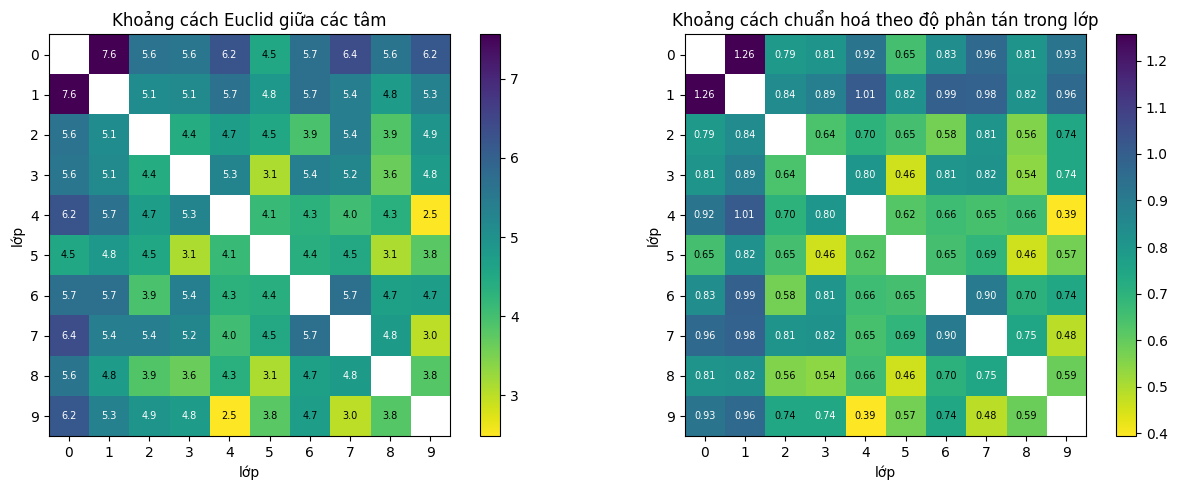

In [19]:
from itertools import combinations

mu_c = means.reshape(10, -1).astype(np.float64)                     # (10, 784): tâm mỗi lớp
dist = np.sqrt(((mu_c[:, None, :] - mu_c[None, :, :]) ** 2).sum(-1))  # (10, 10)
s_c = spread.astype(np.float64)                                      # tổng phương sai trong lớp
sep = dist / np.sqrt((s_c[:, None] + s_c[None, :]) / 2)              # khoảng cách chuẩn hoá

pairs = list(combinations(range(10), 2))                             # 45 cặp
by_dist = sorted(pairs, key=lambda ij: dist[ij])
by_sep = sorted(pairs, key=lambda ij: sep[ij])
rank_dist = {ij: r + 1 for r, ij in enumerate(by_dist)}
rank_sep = {ij: r + 1 for r, ij in enumerate(by_sep)}

print("5 cặp gần nhất theo khoảng cách Euclid:")
for i, j in by_dist[:5]:
    print(f"  {i}–{j}: Euclid = {dist[i, j]:.2f} | chuẩn hoá = {sep[i, j]:.3f} (hạng {rank_sep[(i, j)]})")
print("5 cặp gần nhất theo khoảng cách chuẩn hoá:")
for i, j in by_sep[:5]:
    print(f"  {i}–{j}: chuẩn hoá = {sep[i, j]:.3f} | Euclid = {dist[i, j]:.2f} (hạng {rank_dist[(i, j)]})")
i, j = by_dist[-1]
print(f"Cặp xa nhất (Euclid): {i}–{j} = {dist[i, j]:.2f}")

D_off = dist + np.diag(np.full(10, np.inf))
print("Lớp gần nhất của mỗi lớp (Euclid):", {k: int(D_off[k].argmin()) for k in range(10)})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, Mx, t, fmt in [(axes[0], dist, "Khoảng cách Euclid giữa các tâm", ".1f"),
                       (axes[1], sep, "Khoảng cách chuẩn hoá theo độ phân tán trong lớp", ".2f")]:
    Mm = np.ma.masked_where(np.eye(10, dtype=bool), Mx)
    im = ax.imshow(Mm, cmap="viridis_r")
    for a in range(10):
        for b in range(10):
            if a != b:
                ax.text(b, a, format(Mx[a, b], fmt), ha="center", va="center", fontsize=7,
                        color="black" if Mx[a, b] < np.median(Mx[~np.eye(10, dtype=bool)]) else "white")
    ax.set(xticks=range(10), yticks=range(10), xlabel="lớp", ylabel="lớp", title=t)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
save_fig(plt.gcf(), "03_centroid_distance")
plt.show()

### 3.2 Hai lớp gần nhau khác nhau ở đâu?

Với mỗi cặp gần nhất theo khoảng cách chuẩn hoá: ảnh trung bình của hai lớp, ảnh hiệu $\mu_i - \mu_j$ (đỏ: lớp $i$ có mực nhiều hơn, xanh: lớp $j$ có mực nhiều hơn), và Fisher score của cặp $(\mu_i - \mu_j)^2 / (\sigma_i^2 + \sigma_j^2)$ tại từng pixel: chỗ sáng là chỗ hai lớp khác nhau rõ so với độ dao động bên trong mỗi lớp.

4–9: Fisher của cặp lớn nhất = 2.17 tại (7, 15) | 50% tổng Fisher của cặp nằm ở 24 pixel
5–8: Fisher của cặp lớn nhất = 1.29 tại (17, 11) | 50% tổng Fisher của cặp nằm ở 26 pixel
3–5: Fisher của cặp lớn nhất = 0.83 tại (11, 16) | 50% tổng Fisher của cặp nằm ở 46 pixel
7–9: Fisher của cặp lớn nhất = 1.14 tại (15, 11) | 50% tổng Fisher của cặp nằm ở 33 pixel


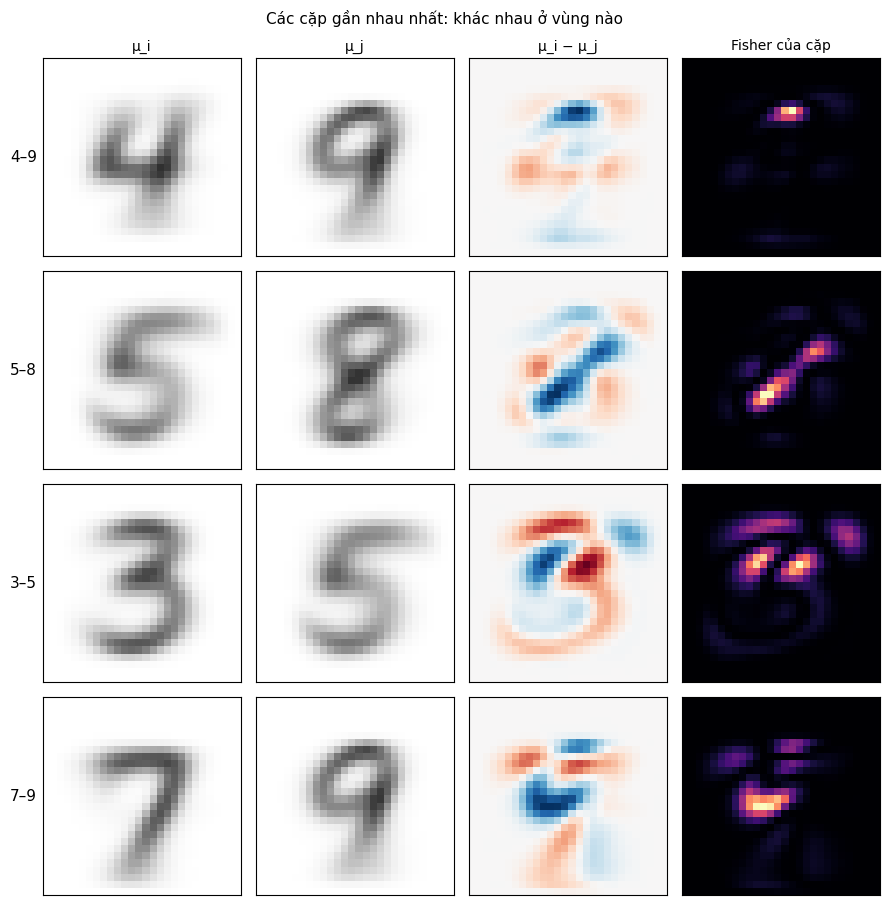

In [20]:
show_pairs = by_sep[:4]
var_c = (stds.reshape(10, -1).astype(np.float64)) ** 2
fig, axes = plt.subplots(len(show_pairs), 4, figsize=(9, 2.3 * len(show_pairs)))
for r_, (i, j) in enumerate(show_pairs):
    diff_ij = (mu_c[i] - mu_c[j]).reshape(28, 28)
    with np.errstate(invalid="ignore", divide="ignore"):
        f_ij = ((mu_c[i] - mu_c[j]) ** 2 / (var_c[i] + var_c[j])).reshape(28, 28)
    v = np.abs(diff_ij).max()
    axes[r_, 0].imshow(means[i], cmap="Greys", vmin=0, vmax=1)
    axes[r_, 1].imshow(means[j], cmap="Greys", vmin=0, vmax=1)
    axes[r_, 2].imshow(diff_ij, cmap="RdBu_r", vmin=-v, vmax=v)
    axes[r_, 3].imshow(np.nan_to_num(f_ij), cmap="magma")
    axes[r_, 0].set_ylabel(f"{i}–{j}", rotation=0, ha="right", va="center", fontsize=11)
    f_sorted = np.sort(np.nan_to_num(f_ij).ravel())[::-1]
    n_half = int(np.searchsorted(np.cumsum(f_sorted) / f_sorted.sum(), 0.5)) + 1
    r_max, c_max = (int(v) for v in np.unravel_index(np.nanargmax(f_ij), (28, 28)))
    print(f"{i}–{j}: Fisher của cặp lớn nhất = {np.nanmax(f_ij):.2f} tại ({r_max}, {c_max}) | "
          f"50% tổng Fisher của cặp nằm ở {n_half} pixel")
for c_, t in enumerate(["μ_i", "μ_j", "μ_i − μ_j", "Fisher của cặp"]):
    axes[0, c_].set_title(t, fontsize=10)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Các cặp gần nhau nhất: khác nhau ở vùng nào", fontsize=11)
plt.tight_layout()
save_fig(plt.gcf(), "03_pair_differences")
plt.show()

### 3.3 Fisher score theo pixel (cả 10 lớp)

Với pixel $p$:

$$F_p = \frac{\sum_k n_k (\mu_{kp} - \mu_p)^2}{\sum_k n_k \sigma_{kp}^2},$$

tức phương sai giữa các lớp chia cho phương sai trong lớp. $F_p$ lớn nghĩa là chỉ nhìn riêng pixel đó cũng đã phân biệt được phần nào các lớp. Dead pixel có mẫu số bằng 0 nên bỏ qua; pixel gần như chết (tần suất < 0,1%) cũng bị che vì ước lượng không đáng tin.

Số pixel tính Fisher: 596 | F lớn nhất = 0.733 | trung vị = 0.148
  50% tổng Fisher nằm ở 129 pixel
  90% tổng Fisher nằm ở 347 pixel
20 pixel có F lớn nhất (hàng, cột): [(12, 14), (13, 14), (16, 13), (14, 14), (19, 10), (15, 14), (14, 17), (18, 10), (15, 13), (20, 8), (17, 13), (13, 22), (13, 13), (18, 11), (19, 11), (16, 14), (12, 22), (21, 8), (19, 9), (12, 15)]
Tương quan giữa F và tần suất có mực (pixel tin cậy): 0.678


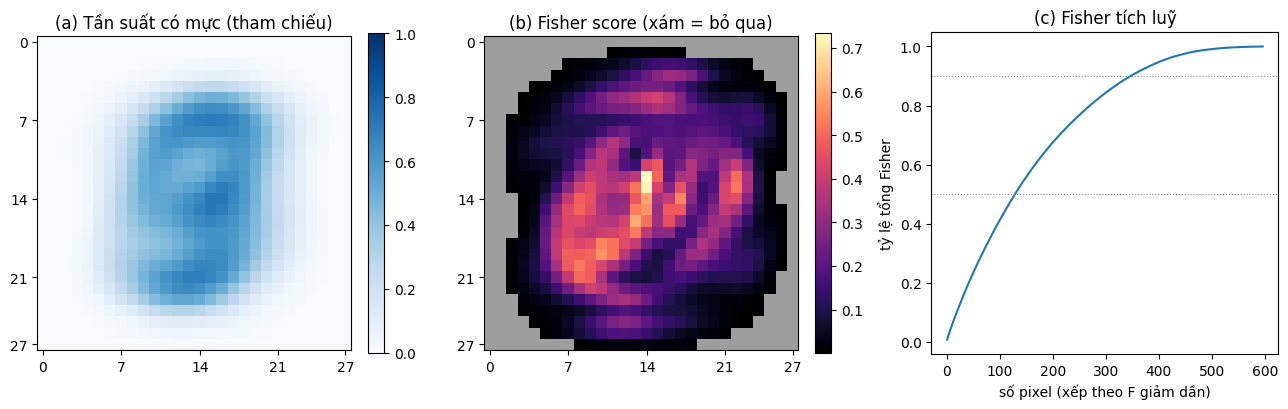

In [21]:
n_k = np.bincount(y_train, minlength=10).astype(np.float64)
mu_all = (n_k[:, None] * mu_c).sum(0) / n_k.sum()
between = (n_k[:, None] * (mu_c - mu_all) ** 2).sum(0)
within_v = (n_k[:, None] * var_c).sum(0)
reliable = (freq >= 0.001).ravel()
fisher = np.full(784, np.nan)
fisher[reliable] = between[reliable] / within_v[reliable]

fv = fisher[reliable]
order_f = np.sort(fv)[::-1]
cum_f = np.cumsum(order_f) / order_f.sum()
print(f"Số pixel tính Fisher: {reliable.sum()} | F lớn nhất = {fv.max():.3f} | trung vị = {np.median(fv):.3f}")
for t in (0.5, 0.9):
    print(f"  {t:.0%} tổng Fisher nằm ở {int(np.searchsorted(cum_f, t)) + 1} pixel")

top20 = np.argsort(np.nan_to_num(fisher, nan=-1))[::-1][:20]
print("20 pixel có F lớn nhất (hàng, cột):", [tuple(int(v) for v in divmod(p_, 28)) for p_ in top20])
print(f"Tương quan giữa F và tần suất có mực (pixel tin cậy): {np.corrcoef(fv, freq.ravel()[reliable])[0, 1]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
im = axes[0].imshow(freq, cmap="Blues", vmin=0, vmax=1)
axes[0].set_title("(a) Tần suất có mực (tham chiếu)")
fig.colorbar(im, ax=axes[0], fraction=0.046)
F_img = np.ma.masked_invalid(fisher.reshape(28, 28))
cmap_f = plt.get_cmap("magma").copy(); cmap_f.set_bad("#9e9e9e")
im = axes[1].imshow(F_img, cmap=cmap_f)
axes[1].set_title("(b) Fisher score (xám = bỏ qua)")
fig.colorbar(im, ax=axes[1], fraction=0.046)
axes[2].plot(np.arange(1, len(cum_f) + 1), cum_f)
for t in (0.5, 0.9):
    axes[2].axhline(t, ls=":", c="gray", lw=0.8)
axes[2].set(xlabel="số pixel (xếp theo F giảm dần)", ylabel="tỷ lệ tổng Fisher", title="(c) Fisher tích luỹ")
for ax in axes[:2]:
    ax.set_xticks([0, 7, 14, 21, 27]); ax.set_yticks([0, 7, 14, 21, 27])
plt.tight_layout()
save_fig(plt.gcf(), "03_fisher_score")
plt.show()

### Kết luận mục 3

**Nhận xét**

- **Cặp gần nhau nhất**: theo Euclid là 4–9 (2,48), 7–9 (2,99), rồi 3–5 và 5–8 (cùng 3,11); theo khoảng cách chuẩn hoá là 4–9 (0,393), 5–8 (0,456), 3–5 (0,457). Cả hai cách đo cho cùng 5 cặp đầu (4–9, 7–9, 5–8, 3–5, 3–8), chỉ khác thứ tự. Cặp xa nhất là 0–1 (7,56): lớp nhiều mực nhất và lớp ít mực nhất. Số 1 có tâm gần nhất với số 8.
- **Khác nhau ở đâu**: 4–9 khác ở đỉnh chữ số (số 9 khép vòng phía trên, số 4 để hở); 5–8 khác ở nét chéo giữa ảnh của số 8; 3–5 khác ở nửa trên (số 5 có nét dọc bên trái, số 3 có nét cong vào giữa); 7–9 khác ở phần dưới vòng tròn của số 9. Một nửa tổng Fisher của mỗi cặp chỉ nằm ở 24–46 pixel: khác biệt dồn vào một vùng nhỏ, phần còn lại của hai chữ số gần như trùng nhau.
- **Fisher theo pixel**: F lớn nhất 0,733, tập trung ở cột giữa ảnh (hàng 12–16, cột 13–14), góc dưới trái (hàng 18–21, cột 7–11) và mép phải (hàng 12–13, cột 22). 50% tổng Fisher nằm ở 129 pixel, 90% ở 347 pixel (trên 596 pixel tin cậy). Tương quan giữa F và tần suất có mực là 0,678: vị trí nhiều mực thường cũng là vị trí phân biệt tốt, nhưng không hoàn toàn trùng nhau.

**Hệ quả cho mô hình** (định hướng; kiểm chứng ở phần thí nghiệm)

| Phát hiện | Ảnh hưởng | Định hướng |
|---|---|---|
| Tâm gần nhau nhất: 4–9, 7–9, 5–8, 3–5, 3–8 (cả hai cách đo); khoảng cách chuẩn hoá của 4 cặp đầu dưới 0,5 | Đây là các cặp có nguy cơ bị nhầm nhiều nhất, rõ nhất ở Multinomial NB và Logistic Regression: cả hai cho ranh giới tuyến tính, và Multinomial NB so ảnh với một khuôn mẫu cho mỗi lớp | Theo dõi riêng các cặp này trong ma trận nhầm lẫn của mọi mô hình |
| Khác biệt giữa cặp gần nhau chỉ nằm ở vùng nhỏ (24–46 pixel giữ một nửa Fisher của cặp) | Random Forest chia nhánh theo từng pixel nên dùng trực tiếp được những vùng nhỏ này; MLP cũng học được tổ hợp phi tuyến | Giả thuyết: Random Forest và MLP giảm lỗi ở các cặp này nhiều hơn hai mô hình tuyến tính |
| Fisher dồn vào 129 pixel (50%) ở giữa ảnh | Mọi mô hình | Một thước đo độc lập với mô hình: so với độ quan trọng của mọi mô hình bằng cùng một cách đo (H4, `compare_models`) |
| Tâm các lớp tách nhau rõ (từ 2,48 đến 7,56) | Phân loại theo tâm gần nhất đã có cơ sở | Dùng bộ phân loại tâm gần nhất làm mốc thấp nhất (baseline) ở phần thí nghiệm |


## **4. Kiểm tra validation và test**
Chỉ so sánh cấu trúc với train; không dùng để ra quyết định.

### 4.1 Validation

- Các vị trí dead trên train có còn bằng 0 trên validation không?
- Tỷ lệ pixel nền và lượng mực trung bình theo lớp của validation có khớp train không?

Vị trí dead của train vẫn bằng 0 trên val: 67 / 72 | tổng mực trên val tại các vị trí này: 0.7137
  ( 1,  4) vòng 1: 1 ảnh val có mực, lớn nhất = 0.0627
  ( 2,  2) vòng 2: 1 ảnh val có mực, lớn nhất = 0.2510
  ( 7,  0) vòng 0: 1 ảnh val có mực, lớn nhất = 0.1843
  (16,  0) vòng 0: 1 ảnh val có mực, lớn nhất = 0.1569
  (19,  0) vòng 0: 1 ảnh val có mực, lớn nhất = 0.0588

Tỷ lệ pixel = 0: train 80.86% | val 80.96%

Lượng mực trung bình theo lớp (train | val | lệch):
  lớp 0:  135.8 |  136.4 | +0.43%
  lớp 1:   59.5 |   60.1 | +1.03%
  lớp 2:  117.0 |  116.0 | -0.84%
  lớp 3:  111.0 |  110.7 | -0.27%
  lớp 4:   95.3 |   94.3 | -1.10%
  lớp 5:  101.0 |  100.8 | -0.12%
  lớp 6:  107.9 |  106.2 | -1.55%
  lớp 7:   89.9 |   89.2 | -0.80%
  lớp 8:  117.8 |  117.3 | -0.42%
  lớp 9:   96.3 |   95.1 | -1.29%


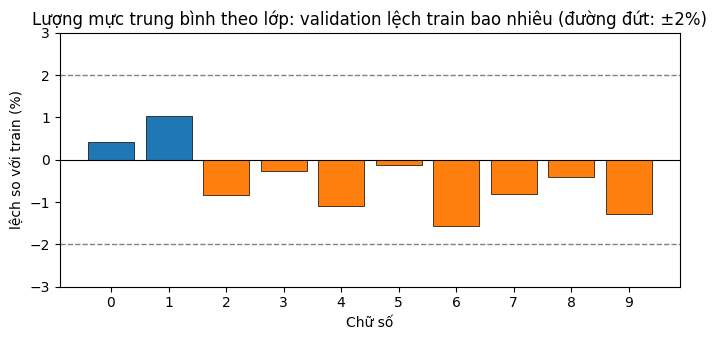

In [22]:
val_max_at_dead = X_val[:, dead].max(axis=0)          # giá trị lớn nhất trên val tại 71 vị trí dead của train
print(f"Vị trí dead của train vẫn bằng 0 trên val: {(val_max_at_dead == 0).sum()} / {dead.sum()} "
      f"| tổng mực trên val tại các vị trí này: {X_val[:, dead].sum():.4f}")
rows_dead, cols_dead = np.where(dead)
for r_, c_, mx in zip(rows_dead, cols_dead, val_max_at_dead):
    if mx > 0:
        print(f"  ({r_:2d}, {c_:2d}) vòng {ring[r_, c_]}: {(X_val[:, r_, c_] > 0).sum()} ảnh val có mực, lớn nhất = {mx:.4f}")

print(f"\nTỷ lệ pixel = 0: train {(X_train == 0).mean():.2%} | val {(X_val == 0).mean():.2%}")

ink_val = X_val.sum(axis=(1, 2))
dev = np.array([(ink_val[y_val == k].mean() - ink_per_class[k]) / ink_per_class[k] * 100 for k in range(10)])
print("\nLượng mực trung bình theo lớp (train | val | lệch):")
for k in range(10):
    print(f"  lớp {k}: {ink_per_class[k]:6.1f} | {ink_val[y_val == k].mean():6.1f} | {dev[k]:+.2f}%")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(range(10), dev, color=["C0" if v >= 0 else "C1" for v in dev], edgecolor="k", linewidth=0.5)
ax.axhline(0, color="k", linewidth=0.8)
for t in (-2, 2):
    ax.axhline(t, color="gray", linestyle="--", linewidth=1)
ax.set(xticks=range(10), xlabel="Chữ số", ylabel="lệch so với train (%)", ylim=(-3, 3),
       title="Lượng mực trung bình theo lớp: validation lệch train bao nhiêu (đường đứt: ±2%)")
plt.tight_layout()
save_fig(fig, "04_val_vs_train_ink")
plt.show()

**Nhận xét**: 67 / 72 vị trí dead của train vẫn bằng 0 trên validation. Năm ngoại lệ đều chỉ có mực ở một ảnh val, giá trị nhỏ (tổng 0,71 trên toàn bộ val); bốn vị trí nằm ở vòng 0–1, ngoài khung 24×24, vị trí còn lại ở vòng 2. Tỷ lệ pixel nền gần như bằng nhau (80,86% so với 80,96%), lượng mực trung bình theo lớp lệch dưới 2%. Validation đại diện tốt cho train, nên các lựa chọn làm trên validation áp dụng được cho dữ liệu cùng phân phối.

### 4.2 Test

In [23]:
# === Kiểm tra tập test: chỉ so sánh với train, không dùng để ra quyết định ===
# Chênh lệch ảnh trung bình của từng lớp giữa train và test
for c in range(10):
    diff = X_train[y_train == c].mean(0) - X_test[y_test == c].mean(0)
    print(c, np.abs(diff).max())

0 0.060442865
1 0.045154095
2 0.0562993
3 0.08098957
4 0.05727631
5 0.07415846
6 0.09434977
7 0.062393278
8 0.097810864
9 0.0788559


**Nhận xét**: chênh lệch lớn nhất giữa ảnh trung bình của train và test, xét từng lớp, nằm trong khoảng 0,045 (lớp 1) đến 0,098 (lớp 8) trên thang [0, 1]. Không có lớp nào lệch bất thường so với các lớp khác, nên các kết luận rút ra trên train có thể áp dụng cho test.


## **5. Tổng hợp: từ EDA tới lựa chọn mô hình**

Đề cho chọn trong ba nhóm: Naive Bayes (Gaussian hoặc Multinomial), phân lớp tuyến tính (Logistic Regression hoặc SVM tuyến tính, huấn luyện bằng gradient descent), Ensemble (Random Forest, AdaBoost hoặc Gradient Boosting); MLP là bắt buộc. Dựa trên các mục 1–3, nhóm chọn **Multinomial NB**, **Logistic Regression** và **Random Forest**. Mục này chỉ lập luận từ tính chất dữ liệu và tính chất của mô hình; mọi kỳ vọng về kết quả được ghi thành giả thuyết ở 5.6 để kiểm chứng ở phần thí nghiệm.

Ngoài việc từng mô hình hợp với dữ liệu (5.1–5.3), bộ lựa chọn này cho một chuỗi so sánh mà mỗi bước chỉ đổi **một** yếu tố. Nhờ vậy, chênh lệch kết quả giữa hai mô hình kề nhau có thể quy về một tính chất dữ liệu mà EDA đã đo:

| So sánh | Giữ nguyên | Thay đổi | Tính chất dữ liệu liên quan |
|---|---|---|---|
| Multinomial NB → Logistic Regression | Dạng hàm quyết định: cả hai đều là softmax của một hàm tuyến tính trên pixel (5.1) | Cách tìm trọng số: đếm mực theo lớp với giả định độc lập, so với tối ưu trực tiếp P(y \| x) | Tương quan giữa các pixel trong cùng lớp (mục 2) |
| Logistic Regression → Random Forest, MLP | Cùng dữ liệu, cùng cách đánh giá | Ranh giới tuyến tính → phi tuyến | Hiệp phương sai khác nhau giữa các lớp (1.2); khác biệt cục bộ giữa các cặp gần nhau (3.2) |


### 5.1 Naive Bayes: chọn Multinomial

**Mô hình.** Với ảnh x (784 pixel, x_p ≥ 0), Multinomial NB ước lượng cho mỗi lớp k một phân phối θ_k trên 784 vị trí:

$$\theta_{kp} = \frac{\sum_{i:\,y_i=k} x_{ip} + \alpha}{\sum_{q}\sum_{i:\,y_i=k} x_{iq} + \alpha d}, \qquad \hat y = \arg\max_k \Big[\log \pi_k + \sum_p x_p \log \theta_{kp}\Big].$$

Tử số là tổng mực của lớp k tại vị trí p, mẫu số là tổng mực của lớp k. Nghĩa là θ_k chính là **ảnh trung bình của lớp k (1.2) chia cho lượng mực trung bình của lớp đó (1.3)**, cộng làm trơn. Hàm quyết định tuyến tính theo x, với trọng số w_kp = log θ_kp.

**Vì sao hợp với dữ liệu**
- *Đặc trưng là lượng mực, không âm.* Pixel nằm trong [0, 1] (mục 0) và "lượng mực" là đại lượng EDA dùng xuyên suốt mục 1. Multinomial NB mô hình hoá đúng đại lượng này, và tham số của nó vẽ lại được thành ảnh, so trực tiếp được với ảnh trung bình ở 1.2.
- *Gaussian NB giả định sai hình dạng phân phối.* Gaussian NB giả định mỗi pixel có phân phối chuẩn trong từng lớp. Dữ liệu thì ngược lại: 80,86% pixel bằng 0, và 69,2% pixel khác 0 có giá trị ≥ 128 (1.1), tức phân phối dồn về hai đầu, không có dạng chuông. Multinomial NB không giả định hình dạng phân phối của từng pixel.
- *Dead pixel không gây lỗi.* Gaussian NB phải chia cho σ², bằng 0 ở 72 vị trí (1.1); Multinomial NB không có phương sai trong công thức.
- *Cùng đầu vào với Logistic Regression.* Multinomial NB làm việc thẳng trên pixel, không cần PCA (vốn tạo giá trị âm), nên so sánh với Logistic Regression ở bảng trên mới đúng nghĩa "chỉ đổi một yếu tố".

**Cần xử lý**
- Giữ pixel [0, 1]; **không** chuẩn hoá (z-score tạo giá trị âm), **không** PCA.
- Làm trơn Laplace α > 0: 116 vị trí gần như chết chỉ có mực ở 1–47 ảnh (1.1), nên nhiều lớp có tổng mực bằng 0 tại đó; không làm trơn thì θ = 0 và log θ = −∞. Chọn α trên validation.
- Tính trong không gian log để tránh tràn số khi cộng 784 số hạng.
- 72 dead pixel có x = 0 trên toàn train nên không góp vào điểm số; bỏ hay giữ chỉ đổi mẫu số làm trơn α·d (d = 784 hoặc 712), ảnh hưởng không đáng kể.

**Cần để ý**
- Giả định độc lập vẫn bị vi phạm (tương quan trong lớp 0,64–0,86, mục 2.2): mỗi nét bút bị đếm như nhiều bằng chứng độc lập, nên xác suất dự đoán dễ bị đẩy về gần 0 hoặc 1.
- θ_k chuẩn hoá về tổng 1, nên mô hình không dùng chênh lệch tổng lượng mực giữa các lớp (số 0: 135,8; số 1: 59,5, mục 1.3).
- Nhân x với hằng số c thì phần log-likelihood nhân c còn log π_k giữ nguyên, nên thang đo ([0, 1] hay [0, 255]) đổi mức tự tin của xác suất. Cố định thang [0, 1] cho mọi thí nghiệm.


### 5.2 Phân lớp tuyến tính: chọn Logistic Regression

**Mô hình.** P(y = k | x) = softmax(Wx + b)_k; cực tiểu cross-entropy + L2 bằng gradient descent. Hàm mất mát lồi và khả vi, nên gradient descent áp dụng trực tiếp; softmax xử lý 10 lớp trong một mô hình.

**Vì sao hợp với dữ liệu**
- *Có nhiều thông tin phân lớp dạng tuyến tính.* Tâm các lớp tách nhau rõ (khoảng cách Euclid từ 2,48 đến 7,56, mục 3.1). Fisher score, tức khả năng phân biệt các lớp của từng pixel dựa trên trung bình, đạt tới 0,733, và 50% tổng Fisher nằm ở 129 pixel (3.3). Đây đúng là loại thông tin mà một tổ hợp tuyến tính các pixel khai thác được.
- *Cùng dạng hàm với Multinomial NB.* Hai mô hình chỉ khác cách tìm W: Multinomial NB tìm bằng cách đếm, dựa trên giả định độc lập; Logistic Regression tối ưu trực tiếp xác suất có điều kiện nên không cần giả định đó. Mục 2 cho thấy giả định độc lập bị vi phạm thật, nên cặp này kiểm chứng đúng điểm đó (cặp so sánh sinh – phân biệt kinh điển, Ng & Jordan, 2002).
- *Không giả định gì về phân phối của x*, nên không vướng dữ liệu gần nhị phân (1.1) như Gaussian NB.

**Vì sao không chọn SVM tuyến tính.** Cùng loại biên (siêu phẳng), nên không thêm được gì về khả năng biểu diễn. Hinge loss không khả vi tại lề nên phải dùng subgradient; đa lớp cần 10 mô hình one-vs-rest hoặc công thức Crammer–Singer; và SVM không cho xác suất, nên không so được log-loss hay mức tự tin với Naive Bayes.

**Cần xử lý**
- Chuẩn hoá **vô hướng** (một mean, một std, fit trên train), như đã chốt ở mục 1; không chuẩn hoá từng pixel.
- L2: các pixel kề nhau tương quan mạnh (r trung bình 0,708, mục 2.1), nên không có L2 thì trọng số không ổn định; 116 pixel gần như chết dễ bị khớp nhiễu.
- Learning rate và số vòng lặp: đặc trưng tương quan mạnh làm bài toán tối ưu có điều kiện số xấu, nên gradient descent có thể hội tụ chậm. Theo dõi loss theo vòng lặp; đây cũng là thí nghiệm siêu tham số mà đề yêu cầu.
- Hướng thử bớt đặc trưng: bỏ pixel hiếm hoặc crop 24×24 (giữ 99,76% mực, mục 1.3); chọn trên validation.

**Cần để ý**
- Bốn cặp có khoảng cách chuẩn hoá giữa hai tâm dưới 0,5 (4–9: 0,393; 5–8: 0,456; 3–5: 0,457; 7–9: 0,484, mục 3.1): so với độ phân tán trong lớp, tâm của hai lớp rất gần nhau.
- Hiệp phương sai các lớp khác nhau (1.2), nên ranh giới tối ưu không phải siêu phẳng; Logistic Regression có thể có trần.
- Đặt ảnh trọng số của mỗi lớp cạnh bản đồ Fisher (3.3) để xem mô hình có dựa vào đúng vùng phân biệt không.


### 5.3 Ensemble: chọn Random Forest

**Mô hình.** Nhiều cây quyết định (CART), mỗi cây học trên một mẫu bootstrap; tại mỗi nút chỉ xét một tập con ngẫu nhiên các pixel (thường √d). Dự đoán bằng bỏ phiếu: mỗi cây một phiếu (Breiman, 2001) hoặc trung bình phân phối lớp ở lá (cách của scikit-learn). Mỗi phép chia là một ngưỡng trên **một** pixel.

**Vì sao hợp với dữ liệu**
- *Ranh giới có thể phi tuyến.* Hiệp phương sai các lớp khác nhau rõ (tổng phương sai trong lớp 22,4–50,8, mục 1.2), nên ranh giới tối ưu không phải siêu phẳng. Random Forest không giả định dạng ranh giới.
- *Khác biệt giữa các cặp gần nhau nằm ở vùng nhỏ.* Một nửa Fisher của mỗi cặp chỉ nằm ở 24–46 pixel (3.2), ví dụ cặp 4–9 khác nhau ở chỗ đỉnh chữ số khép hay hở. Vài phép chia trên đúng những pixel đó là tách được cặp, và đây đúng là kiểu quyết định mà cây tạo ra.
- *Thông tin trải trên nhiều pixel tương quan.* 90% tổng Fisher nằm ở 347 pixel (3.3), và các pixel lân cận mang thông tin trùng nhau (mục 2). Với √784 = 28 pixel ngẫu nhiên mỗi nút, ở nút gốc rút từ 712 pixel không hằng (pixel hằng không được tính vào 28 pixel này), trung bình khoảng 13–14 pixel thuộc nhóm 347 này, nên từng cây vẫn đủ mạnh mà các cây vẫn khác nhau. Random Forest cần đúng hai điều này: cây mạnh và tương quan giữa các cây thấp (Breiman, 2001).
- *Không cần tiền xử lý thang đo.* Phép chia theo ngưỡng không đổi khi biến đổi đơn điệu đặc trưng; 72 dead pixel là đặc trưng hằng nên tự bị bỏ qua.
- *Giải thích được.* Feature importance vẽ thành bản đồ 28×28, đặt cạnh bản đồ Fisher (3.3) và tần suất có mực (1.1). Đề yêu cầu so sánh khả năng giải thích của các mô hình.

**Vì sao không chọn AdaBoost hay Gradient Boosting**
- *Chi phí huấn luyện.* Các cây của Random Forest độc lập nên trồng song song được trên mọi lõi. Gradient Boosting cho 10 lớp phải học 10 cây hồi quy mỗi vòng trên gradient của softmax, tuần tự qua các vòng; AdaBoost đa lớp (SAMME) cũng học tuần tự. Với 50.000 × 784 đặc trưng, đây là khác biệt lớn về thời gian, nhất là khi phải dò siêu tham số nhiều lần.
- *Thí nghiệm siêu tham số rõ ràng.* Thêm cây không làm Random Forest overfit thêm, nên đường "accuracy theo số cây" tăng rồi bão hoà, dễ đọc. Boosting phải cân learning rate với số vòng.
- *Ước lượng lỗi out-of-bag* có sẵn, không tốn thêm dữ liệu. Lưu ý: mỗi mẫu chỉ là OOB của khoảng e⁻¹ ≈ 37% số cây, nên khi rừng ít cây, OOB đánh giá thấp độ chính xác của cả rừng.
- *Đánh đổi:* boosting được tinh chỉnh kỹ thường được báo cáo là chính xác hơn Random Forest. Nhóm chấp nhận đánh đổi này để đổi lấy thời gian huấn luyện và độ ổn định; phần thí nghiệm đo lại đánh đổi này bằng AdaBoost và Gradient Boosting của scikit-learn trên cùng đặc trưng.

**Cần xử lý**
- Chi phí tìm phép chia ở mỗi nút tỷ lệ với m × số mẫu ở nút (m = √d), không phải d. Bỏ pixel viền (72 dead pixel, crop 24×24 hoặc 20×20, mục 1.3) vẫn có thể giảm chi phí vì các pixel này hằng ở hầu hết các nút; mức giảm cần đo khi chọn mặt nạ pixel.
- Pixel gần nhị phân (80,86% bằng 0; 69,2% pixel khác 0 có giá trị ≥ 128, mục 1.1), nên chỉ cần ít ngưỡng ứng viên cho mỗi pixel thay vì thử cả 256 mức; trường hợp cực đoan là một ngưỡng duy nhất, pixel > 0, đúng định nghĩa "có mực" ở 1.1.
- Không bắt buộc giới hạn cây: Random Forest giảm phương sai bằng cách lấy trung bình nhiều cây đầy đủ (Breiman, 2001). `min_samples_leaf` và giới hạn độ sâu là siêu tham số để thử; pixel gần như chết chỉ có lợi cho phép chia ở các nút nhỏ, tầng sâu.
- Siêu tham số chính: số cây (thí nghiệm có biểu đồ), `max_features`.

**Cần để ý**
- Importance bị chia cho các pixel lân cận (mục 2), nên đọc theo vùng.


### 5.4 MLP (bắt buộc)

MLP là mô hình phi tuyến thứ hai, dựa trên cùng các tính chất như Random Forest (1.2, 3.2), nhưng với ranh giới mượt thay vì các phép chia song song trục. Từ EDA: dùng chuẩn hoá vô hướng như Logistic Regression (mục 1); L2 hoặc dropout vì các pixel tương quan mạnh và có 116 pixel gần như chết (mục 1, 2).

**CNN (phần nâng cao: so với MLP).** Ngoài 4 mô hình bắt buộc, nhóm cài thêm một CNN nhỏ (2 khối conv 3×3 → ReLU → max-pool 2×2, rồi một lớp ẩn). Ba tính chất dữ liệu gợi ý tích chập hợp với MNIST hơn MLP:
- *Thông tin cục bộ*: tương quan giữa hai pixel giảm từ r ≈ 0,71 (kề nhau) về ≈ 0 ở khoảng cách 5 (2.1). Một bộ lọc 3×3 dùng chung cho mọi vị trí đủ bao tầm tương quan đó, thay vì học riêng trọng số cho 784 vị trí như MLP.
- *Khác biệt giữa các cặp gần nhau nằm ở vùng nhỏ* (24–46 pixel, 3.2), ví dụ đỉnh số 4 hở hay số 9 khép: đặc trưng cục bộ mà tích chập phát hiện được ở bất kỳ vị trí nào.
- *Vị trí nét lệch vài pixel trong cùng lớp* (ảnh mẫu 1.2): max-pool 2×2 chịu được độ lệch nhỏ đó, còn MLP thấy cùng một nét ở pixel khác như một đặc trưng khác.

Giới hạn: CNN này chỉ chịu được dịch vài pixel, không bất biến với độ nghiêng hay dịch lớn. Kiểm chứng: so CNN với MLP (cùng là mạng nơ-ron, chỉ khác ở tích chập) về accuracy và lỗi ở 5 cặp gần nhau (3.1). Đây là hướng nâng cao, không thuộc các giả thuyết H1–H4 ở 5.6.

### 5.5 Tóm tắt

**Chung cho mọi mô hình** (mục 0.3–0.5, 4): dữ liệu sạch, không trùng và không rò rỉ giữa ba tập; các lớp gần cân bằng (max/min ≈ 1,24) nên không cần resampling, accuracy và F1 macro đều dùng được; validation đại diện tốt cho train nên chọn siêu tham số trên validation là có cơ sở.

| | Multinomial NB | Logistic Regression | Random Forest |
|---|---|---|---|
| Ranh giới | Tuyến tính | Tuyến tính | Phi tuyến, song song trục |
| Đầu vào | Pixel [0, 1], không chuẩn hoá | Chuẩn hoá vô hướng; hướng thử: bỏ pixel hiếm, crop 24×24 | Pixel [0, 1]; hướng thử: bỏ dead pixel, crop 24×24 hoặc 20×20, ít ngưỡng |
| Xử lý bắt buộc | Làm trơn Laplace α | L2; chọn learning rate, số vòng | Không có; thử `min_samples_leaf` / độ sâu trên validation |
| Phát hiện EDA ủng hộ | Đặc trưng không âm, gần nhị phân (1.1); dead pixel (1.1) | Tâm lớp tách rõ; Fisher dồn vào 129 pixel (3.1, 3.3) | Hiệp phương sai khác nhau giữa các lớp (1.2); khác biệt cục bộ 24–46 pixel (3.2) |
| Giới hạn EDA dự báo | Giả định độc lập bị vi phạm (2.2) → xác suất quá tự tin | Ranh giới tuyến tính có trần (1.2, 3.1) | Chi phí tính toán; importance loang (mục 2) |

### 5.6 Giả thuyết để kiểm chứng ở phần thí nghiệm

EDA chỉ đưa ra định hướng. Bốn giả thuyết dưới đây được kiểm chứng trên tập validation (`src/experiments/compare_models.py`); tập test chỉ dùng sau khi mô hình đã chốt. Mỗi giả thuyết nối một phát hiện EDA với một so sánh giữa các mô hình. Bộ phân loại tâm gần nhất (3.1) là mốc trong mọi bảng, không phải giả thuyết; các lựa chọn như mặt nạ pixel, số ngưỡng hay độ sâu cây là chọn siêu tham số trên validation.

| # | Giả thuyết | Cơ sở từ EDA | Cách kiểm chứng |
|---|---|---|---|
| H1 | Logistic Regression chính xác hơn và cho xác suất đáng tin hơn Multinomial NB | Giả định độc lập bị vi phạm (2.2) | So accuracy, log-loss, tỷ lệ dự đoán sai nhưng có xác suất > 0,99 |
| H2 | Random Forest và MLP vượt Logistic Regression | Hiệp phương sai khác nhau giữa các lớp (1.2) | So accuracy, F1 macro |
| H3 | (a) Lỗi của hai mô hình tuyến tính dồn vào các cặp 4–9, 7–9, 5–8, 3–5, 3–8; (b) Random Forest và MLP giảm lỗi ở chính các cặp này mạnh hơn mức giảm lỗi chung | (a) Tâm gần nhau nhất (3.1); (b) hai lớp gần nhau chỉ khác ở 24–46 pixel (3.2), mô hình phi tuyến khai thác được | (a) Tỉ lệ lỗi rơi vào 5 cặp và số cặp nằm trong 5 cặp nhầm nhiều nhất; (b) so với Logistic Regression: phần giảm lỗi ở 5 cặp so với phần giảm tổng lỗi |
| H4 | Vùng ảnh mà mô hình dựa vào trùng với vùng Fisher cao | Fisher dồn ở cột giữa và góc dưới trái (3.3) | Cùng một cách đo cho mọi mô hình: độ giảm accuracy khi hoán vị từng khối 4×4, Spearman với Fisher theo khối; bổ sung: độ quan trọng riêng theo pixel của từng mô hình |
